In [30]:
import pandas as pd

df = pd.read_csv("/Users/zoolutanwar/Desktop/Retail-Analytics-Project/data/walmart-recruiting-store-sales-forecasting/train.csv")
df.head()


,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


In [31]:
df.shape

(421570, 5)

In [32]:
df.columns

Index(['Store', 'Dept', 'Date', 'Weekly_Sales', 'IsHoliday'], dtype='str')

In [33]:
df.dtypes

Store             int64
Dept              int64
Date                str
Weekly_Sales    float64
IsHoliday          bool
dtype: object

In [34]:
df['Date'] = pd.to_datetime(df['Date'])

In [35]:
df.dtypes

Store                    int64
Dept                     int64
Date            datetime64[us]
Weekly_Sales           float64
IsHoliday                 bool
dtype: object

In [36]:
df.isnull().sum()

Store           0
Dept            0
Date            0
Weekly_Sales    0
IsHoliday       0
dtype: int64

In [37]:
df.duplicated().sum()

np.int64(0)

In [38]:
df['Weekly_Sales'].describe()


count    421570.000000
mean      15981.258123
std       22711.183519
min       -4988.940000
25%        2079.650000
50%        7612.030000
75%       20205.852500
max      693099.360000
Name: Weekly_Sales, dtype: float64

In [39]:
(df['Weekly_Sales'] < 0).sum()


np.int64(1285)

In [40]:
negative_sales = df[df['Weekly_Sales'] < 0]

negative_sales.head(10)

,Store,Dept,Date,Weekly_Sales,IsHoliday
846,1,6,2012-08-10,-139.65,False
2384,1,18,2012-05-04,-1.27,False
6048,1,47,2010-02-19,-863.00,False
6049,1,47,2010-03-12,-698.00,False
6051,1,47,2010-10-08,-58.00,False
6056,1,47,2011-04-08,-298.00,False
6057,1,47,2011-07-08,-198.00,False
6061,1,47,2011-10-14,-498.00,False
6062,1,47,2011-12-23,-498.00,False
6063,1,47,2012-02-17,-198.00,False


In [41]:
negative_sales['Dept'].value_counts().head(10)

Dept
47    254
18    180
54    146
19     87
94     77
80     68
49     67
59     44
72     34
78     33
Name: count, dtype: int64

In [42]:
negative_sales['IsHoliday'].value_counts()

IsHoliday
False    1187
True       98
Name: count, dtype: int64

In [43]:
df.groupby('IsHoliday')['Weekly_Sales'].agg(
    total_observations='count',
    negative_sales=lambda x: (x < 0).sum()
)

,total_observations,negative_sales
IsHoliday,,
False,391909,1187
True,29661,98


In [44]:
result = df.groupby('IsHoliday')['Weekly_Sales'].agg(
    total_observations='count',
    negative_sales=lambda x: (x < 0).sum()
)

result['negative_sales_rate'] = (
    result['negative_sales'] / result['total_observations']
) * 100

result

,total_observations,negative_sales,negative_sales_rate
IsHoliday,,,
False,391909,1187,0.302876
True,29661,98,0.330400


# EDA

Matplotlib is building the font cache; this may take a moment.


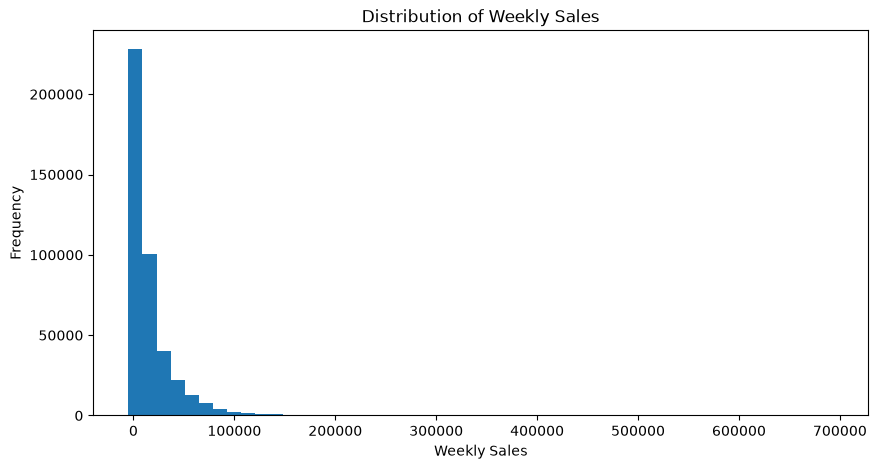

In [46]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(df['Weekly_Sales'], bins=50)

plt.title('Distribution of Weekly Sales')
plt.xlabel('Weekly Sales')
plt.ylabel('Frequency')

plt.show()

In [47]:
Q1 = df['Weekly_Sales'].quantile(0.25)
Q3 = df['Weekly_Sales'].quantile(0.75)

print("Q1:", Q1)
print("Q3:", Q3)

Q1: 2079.6499999999996
Q3: 20205.8525


In [48]:
IQR = Q3 - Q1

print("IQR:", IQR)

IQR: 18126.2025


In [49]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Lower Bound: -25109.653749999998
Upper Bound: 47395.15625


In [50]:
outliers = df[
    (df['Weekly_Sales'] < lower_bound) |
    (df['Weekly_Sales'] > upper_bound)
]

print("Total outliers:", len(outliers))

Total outliers: 35521


In [51]:
upper_outliers = df[df['Weekly_Sales'] > upper_bound]

lower_outliers = df[df['Weekly_Sales'] < lower_bound]

print("Upper outliers:", len(upper_outliers))
print("Lower outliers:", len(lower_outliers))

Upper outliers: 35521
Lower outliers: 0


In [52]:
upper_outliers['Store'].value_counts().head(10)

Store
4     2224
20    2096
10    2030
14    1997
13    1933
2     1779
27    1589
39    1400
31    1341
6     1340
Name: count, dtype: int64

In [53]:
upper_outliers['Dept'].value_counts().head(10)

Dept
38    4348
95    4242
92    4102
90    2832
40    2797
72    2746
2     2732
91    2008
94    1786
93    1115
Name: count, dtype: int64

In [54]:
upper_outliers['Weekly_Sales'].describe()

count     35521.000000
mean      75070.033498
std       30239.976261
min       47395.570000
25%       55099.420000
50%       65890.020000
75%       84017.980000
max      693099.360000
Name: Weekly_Sales, dtype: float64

In [55]:
upper_outliers['IsHoliday'].value_counts()

IsHoliday
False    32903
True      2618
Name: count, dtype: int64

In [56]:
upper_outlier_summary = df.groupby('IsHoliday').agg(
    total_observations=('Weekly_Sales', 'count'),
    upper_outliers=('Weekly_Sales', lambda x: (x > upper_bound).sum())
)

upper_outlier_summary['outlier_rate'] = (
    upper_outlier_summary['upper_outliers'] /
    upper_outlier_summary['total_observations']
) * 100

upper_outlier_summary

,total_observations,upper_outliers,outlier_rate
IsHoliday,,,
False,391909,32903,8.395571
True,29661,2618,8.826405


In [57]:
daily_sales = df.groupby('Date')['Weekly_Sales'].sum()

daily_sales.head()

Date
2010-02-05    49750740.50
2010-02-12    48336677.63
2010-02-19    48276993.78
2010-02-26    43968571.13
2010-03-05    46871470.30
Name: Weekly_Sales, dtype: float64

In [58]:
department_avg_sales = df.groupby('Dept')['Weekly_Sales'].mean()

department_avg_sales.head(10)

Dept
1     19213.485088
2     43607.020113
3     11793.698516
4     25974.630238
5     21365.583515
6      4747.856188
7     24161.237413
8     30191.263517
9     20206.681878
10    18321.272351
Name: Weekly_Sales, dtype: float64

In [59]:
department_avg_sales.sort_values(ascending=False).head(10)

Dept
92    75204.870531
95    69824.423080
38    61090.619568
72    50566.515417
65    45441.706224
90    45232.084488
40    44900.702727
2     43607.020113
91    33687.910758
94    33405.883963
Name: Weekly_Sales, dtype: float64

In [62]:
avgsalesstore = df.groupby('Store')['Weekly_Sales'].mean()
avgsalesstore.head()

Store
1    21710.543621
2    26898.070031
3     6373.033983
4    29161.210415
5     5053.415813
Name: Weekly_Sales, dtype: float64

In [63]:
avgsalesstore.sort_values(ascending=False).head(10)

Store
20    29508.301592
4     29161.210415
14    28784.851727
13    27355.136891
2     26898.070031
10    26332.303819
27    24826.984536
6     21913.243624
1     21710.543621
39    21000.763562
Name: Weekly_Sales, dtype: float64

In [64]:
df.groupby('IsHoliday')['Weekly_Sales'].mean()

IsHoliday
False    15901.445069
True     17035.823187
Name: Weekly_Sales, dtype: float64

In [72]:
df['Month'] = df['Date'].dt.month

In [73]:
df[['Date', 'Month']].head(10)

,Date,Month
0,2010-02-05,2
1,2010-02-12,2
2,2010-02-19,2
3,2010-02-26,2
4,2010-03-05,3
5,2010-03-12,3
6,2010-03-19,3
7,2010-03-26,3
8,2010-04-02,4
9,2010-04-09,4


In [77]:
df.groupby('Month')['Weekly_Sales'].sum()

Month
1     3.325984e+08
2     5.687279e+08
3     5.927859e+08
4     6.468598e+08
5     5.571256e+08
6     6.226299e+08
7     6.500010e+08
8     6.130902e+08
9     5.787612e+08
10    5.847848e+08
11    4.130157e+08
12    5.768386e+08
Name: Weekly_Sales, dtype: float64

In [81]:
monthly_sales = df.groupby('Month')['Weekly_Sales'].sum()

monthly_sales = monthly_sales / 10000000

print(monthly_sales,'crores')

Month
1     33.259844
2     56.872789
3     59.278590
4     64.685978
5     55.712557
6     62.262989
7     65.000098
8     61.309021
9     57.876118
10    58.478479
11    41.301573
12    57.683864
Name: Weekly_Sales, dtype: float64 crores


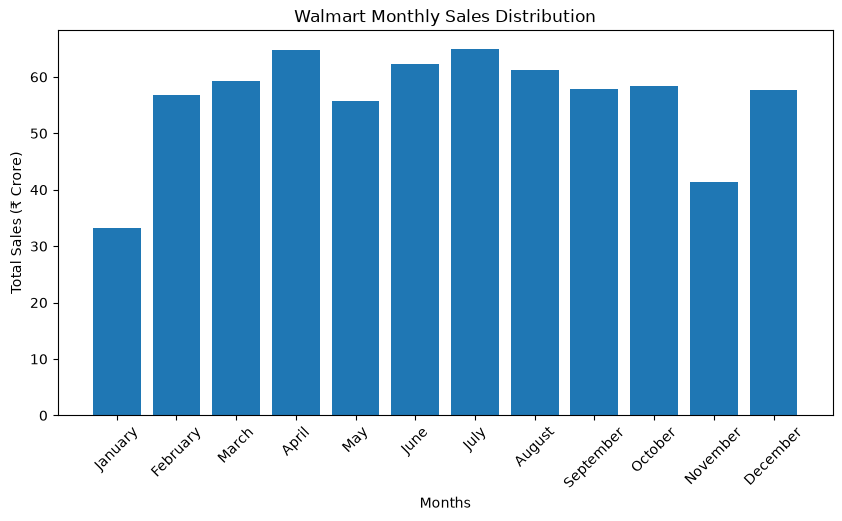

In [89]:
plt.figure(figsize=(10, 5))
plt.bar(monthly_sales.index,monthly_sales)
plt.title("Walmart Monthly Sales Distribution") 
plt.xlabel('Months')
import calendar
plt.xticks(monthly_sales.index,[calendar.month_name[i] for i in monthly_sales.index],rotation=45)
plt.ylabel("Total Sales (₹ Crore)") 
plt.show() #to display the graph.

In [90]:
df['Year'] = df['Date'].dt.year

In [91]:
df[['Date', 'Year']].head(10)

,Date,Year
0,2010-02-05,2010
1,2010-02-12,2010
2,2010-02-19,2010
3,2010-02-26,2010
4,2010-03-05,2010
5,2010-03-12,2010
6,2010-03-19,2010
7,2010-03-26,2010
8,2010-04-02,2010
9,2010-04-09,2010


In [94]:
df.groupby('Year')['Weekly_Sales'].sum()

Year
2010    2.288886e+09
2011    2.448200e+09
2012    2.000133e+09
Name: Weekly_Sales, dtype: float64

In [97]:
a= df.groupby('Year')['Weekly_Sales'].mean()

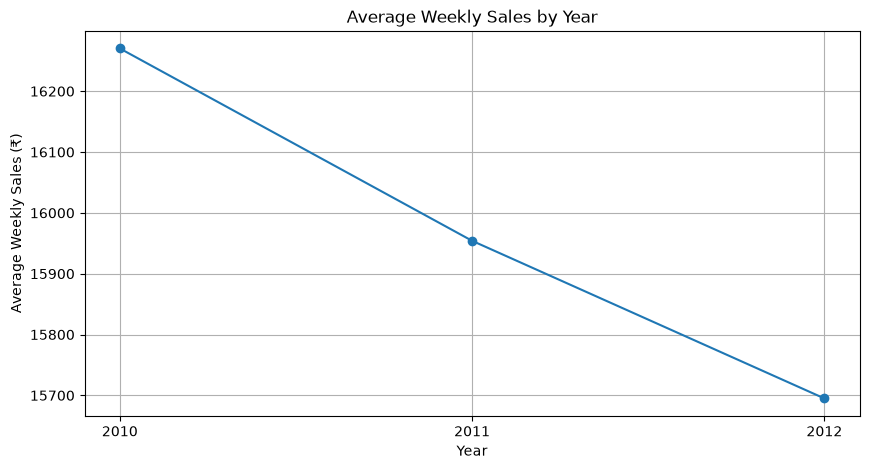

In [100]:
plt.figure(figsize=(10, 5))

plt.plot(a.index, a.values, marker='o')

plt.xticks([2010, 2011, 2012])

plt.title('Average Weekly Sales by Year')
plt.xlabel('Year')
plt.ylabel('Average Weekly Sales (₹)')

plt.grid(True)
plt.show()

In [101]:
df.groupby(['Year', 'Dept'])['Weekly_Sales'].sum()

Year  Dept
2010  1       4.284353e+07
      2       9.405293e+07
      3       2.509114e+07
      4       5.557729e+07
      5       5.177156e+07
                  ...     
2012  95      1.378918e+08
      96      2.356474e+07
      97      2.740097e+07
      98      1.150465e+07
      99      9.487876e+04
Name: Weekly_Sales, Length: 243, dtype: float64

In [102]:
year_dept_sales = df.groupby(['Year', 'Dept'])['Weekly_Sales'].sum()

year_dept_sales = year_dept_sales.unstack(level=0)

year_dept_sales.head()

Year,2010,2011,2012
Dept,,,
1,42843534.38,4.534931e+07,35445927.76
2,94052933.38,1.015053e+08,85052985.88
3,25091137.08,2.701822e+07,23783096.65
4,55577287.55,6.056611e+07,51003352.42
5,51771563.79,5.036340e+07,33472398.70


In [103]:
dept_change = (
    (year_dept_sales[2012] - year_dept_sales[2010])
    / year_dept_sales[2010]
) * 100

dept_change.sort_values().head(10)

Dept
47   -147.294199
51    -98.597210
54    -86.121525
59    -84.391124
78    -78.898011
18    -64.980912
45    -59.819510
6     -51.886819
55    -46.862128
5     -35.345977
dtype: float64

In [104]:
year_dept_sales.loc[47]

Year
2010   -2315.95
2011   -3742.29
2012    1095.31
Name: 47, dtype: float64

In [105]:
df[df['Dept'] == 47][['Store', 'Date', 'Weekly_Sales']].head(10)

,Store,Date,Weekly_Sales
6047,1,2010-02-05,70.0
6048,1,2010-02-19,-863.0
6049,1,2010-03-12,-698.0
6050,1,2010-04-09,14.0
6051,1,2010-10-08,-58.0
6052,1,2010-10-22,60.0
6053,1,2010-11-12,20.0
6054,1,2010-12-24,89.0
6055,1,2011-03-11,0.0
6056,1,2011-04-08,-298.0


In [106]:
dept47 = df[df['Dept'] == 47]

dept47.groupby('Store')['Weekly_Sales'].sum()

Store
1    -2562.00
2      397.50
3      311.00
4      305.97
5      426.00
6     -756.42
7     -158.50
8      503.50
9      -55.26
10   -2329.00
11      23.00
12    -965.78
13    2212.94
14    -186.67
15     343.50
16   -1039.08
17     109.26
18     343.00
19     569.03
20    -378.58
21     426.97
22     231.12
23    -551.50
24    -188.45
25     455.79
26    1242.34
27     134.00
28    1682.92
29     191.74
31    -303.92
32     -84.00
34    -947.03
35   -3567.18
39      23.60
40    -241.56
41     479.86
45   -1061.04
Name: Weekly_Sales, dtype: float64

In [107]:
(dept47['Weekly_Sales'] < 0).sum()


np.int64(254)

In [108]:
len(dept47)

646

In [110]:
negativecount=(dept47["Weekly_Sales"]<0).sum()
total=len(dept47)
rate=(negativecount/total)*100
print(rate)

39.318885448916404


In [116]:
negative_Sales= df.groupby('Dept')["Weekly_Sales"].apply(
    lambda x: (x<0).mean()
)
negative_Sales
print(negative_Sales>0)
negative_Sales.sort_values(ascending=False).head(10)

Dept
1     False
2     False
3     False
4     False
5      True
      ...  
95    False
96     True
97     True
98     True
99     True
Name: Weekly_Sales, Length: 81, dtype: bool


Dept
47    0.393189
78    0.140426
77    0.106667
18    0.035792
54    0.030627
19    0.021122
51    0.017934
49    0.014949
94    0.013544
45    0.012397
Name: Weekly_Sales, dtype: float64

In [121]:
dept78=df[df["Dept"]==78]
negativecount1=(dept78["Weekly_Sales"]<0).sum()
total1=len(dept78)
rate1=(negativecount1/total1)*100
print(rate1)

14.042553191489363


In [122]:
dept77 = df[df["Dept"] == 77]

negativecount2 = (dept77["Weekly_Sales"] < 0).sum()
total2 = len(dept77)

rate2 = (negativecount2 / total2) * 100

print("Negative observations:", negativecount2)
print("Total observations:", total2)
print("Negative sales rate:", rate2)

Negative observations: 16
Total observations: 150
Negative sales rate: 10.666666666666668


In [124]:
dept47.groupby('Year')['Weekly_Sales'].agg(
    total_observations='count',
    negative_observations=lambda x: (x < 0).sum()
)
dept47_yearly = dept47.groupby('Year')['Weekly_Sales'].apply(
    lambda x: (x < 0).mean() * 100
)

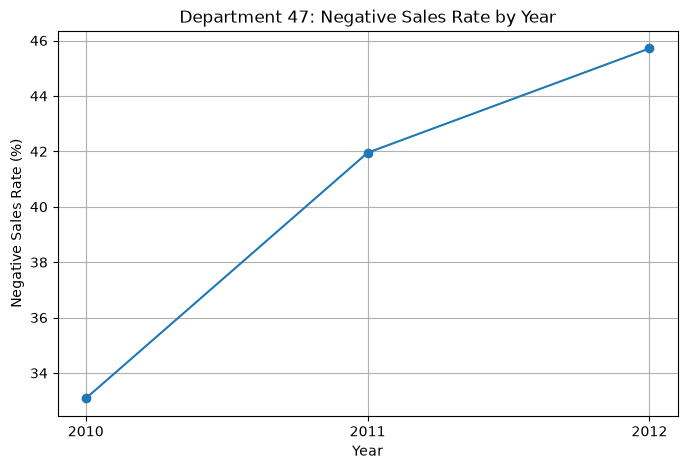

In [127]:
plt.figure(figsize=(8, 5))
plt.plot(dept47_yearly.index, dept47_yearly.values, marker='o')
plt.title('Department 47: Negative Sales Rate by Year')
plt.xlabel('Year')
plt.ylabel('Negative Sales Rate (%)')
plt.xticks([2010,2011,2012])
plt.grid(True)
plt.show()


In [137]:
(dept47.groupby('Store')["Weekly_Sales"].agg(
    total_observations="count",
    negative_observations= lambda x:(x<0).sum()
)).sort_values(by='negative_observations',ascending=False).head()

,total_observations,negative_observations
Store,,
35,36,20
10,36,19
12,22,13
19,24,12
27,23,11


In [138]:
store_negative_rate = dept47.groupby('Store')['Weekly_Sales'].apply(
    lambda x: (x < 0).mean() * 100
)

store_negative_rate.sort_values(ascending=False).head(10)

Store
17    71.428571
23    66.666667
31    60.000000
12    59.090909
34    58.333333
24    57.142857
35    55.555556
15    53.333333
10    52.777778
22    50.000000
Name: Weekly_Sales, dtype: float64

In [139]:
store17_dept47 = dept47[dept47['Store'] == 17]

store17_dept47.groupby('Year')['Weekly_Sales'].agg(
    total_observations='count',
    negative_observations=lambda x: (x < 0).sum()
)

,total_observations,negative_observations
Year,,
2010,3,2
2011,2,1
2012,2,2


In [140]:
store17_dept47[['Date', 'Weekly_Sales']].sort_values('Date')

,Date,Weekly_Sales
163365,2010-02-19,-17.74
163366,2010-03-19,-20.00
163367,2010-04-23,313.00
163368,2011-01-21,-63.00
163369,2011-09-23,224.00
163370,2012-03-02,-259.00
163371,2012-06-15,-68.00


In [141]:
store17 = df[df['Store'] == 17]

store17['Weekly_Sales'].describe()

count      9864.000000
mean      12954.393636
std       16299.024131
min        -259.000000
25%        2182.490000
50%        6758.145000
75%       17007.990000
max      194660.520000
Name: Weekly_Sales, dtype: float64

In [143]:
negative_store17 = (store17['Weekly_Sales'] < 0).sum()

total_store17 = len(store17)

negative_rate_store17 = (negative_store17 / total_store17) * 100

print("Negative observations:", negative_store17)
print("Total observations:", total_store17)
print("Negative sales rate:", negative_rate_store17)

Negative observations: 49
Total observations: 9864
Negative sales rate: 0.4967558799675588


In [144]:
store_negative_rates = df.groupby('Store')['Weekly_Sales'].apply(
    lambda x: (x < 0).mean() * 100
)

store_negative_rates.sort_values(ascending=False).head(10)

Store
35    1.301427
42    0.632820
18    0.527437
17    0.496756
10    0.484731
15    0.454500
22    0.423204
16    0.402414
36    0.401800
39    0.384693
Name: Weekly_Sales, dtype: float64

In [145]:
store35 = df[df['Store'] == 35]

negative_count35 = (store35['Weekly_Sales'] < 0).sum()
total_count35 = len(store35)

negative_rate35 = (negative_count35 / total_count35) * 100

print(negative_count35, total_count35, negative_rate35)

124 9528 1.3014273719563392


In [146]:
store35.groupby('Dept')['Weekly_Sales'].agg(
    total_observations='count',
    negative_observations=lambda x: (x < 0).sum()
).sort_values(
    by='negative_observations',
    ascending=False
).head(10)

,total_observations,negative_observations
Dept,,
80,134,25
47,36,20
49,57,20
94,92,14
19,10,10
18,128,8
54,136,8
59,136,7
77,5,3


In [147]:
store35_negative_rates = store35.groupby('Dept')['Weekly_Sales'].apply(
    lambda x: (x < 0).mean() * 100
)

store35_negative_rates.sort_values(ascending=False).head(10)

Dept
19    100.000000
77     60.000000
47     55.555556
49     35.087719
80     18.656716
96     16.666667
94     15.217391
18      6.250000
54      5.882353
59      5.147059
Name: Weekly_Sales, dtype: float64

In [149]:
store35.groupby('Dept')['Weekly_Sales'].agg(
    total_observations='count',
    negative_observations=lambda x: (x < 0).sum()
)

,total_observations,negative_observations
Dept,,
1,143,0
2,143,0
3,143,0
4,143,0
5,143,0
...,...,...
94,92,14
95,143,0
96,12,2


In [150]:
store35_summary = store35.groupby('Dept')['Weekly_Sales'].agg(
    total_observations='count',
    negative_observations=lambda x: (x < 0).sum(),
    negative_rate=lambda x: (x < 0).mean() * 100
)

store35_summary.sort_values(
    by='negative_rate',
    ascending=False
).head(10)

,total_observations,negative_observations,negative_rate
Dept,,,
19,10,10,100.000000
77,5,3,60.000000
47,36,20,55.555556
49,57,20,35.087719
80,134,25,18.656716
96,12,2,16.666667
94,92,14,15.217391
18,128,8,6.250000
54,136,8,5.882353


In [152]:
selected_depts = df[df['Dept'].isin([47, 49, 80])]
selected_depts

,Store,Dept,Date,Weekly_Sales,IsHoliday,Month,Year
6047,1,47,2010-02-05,70.00,False,2,2010
6048,1,47,2010-02-19,-863.00,False,2,2010
6049,1,47,2010-03-12,-698.00,False,3,2010
6050,1,47,2010-04-09,14.00,False,4,2010
6051,1,47,2010-10-08,-58.00,False,10,2010
...,...,...,...,...,...,...,...
419721,45,80,2012-09-28,563.07,False,9,2012
419722,45,80,2012-10-05,697.34,False,10,2012
419723,45,80,2012-10-12,762.58,False,10,2012
419724,45,80,2012-10-19,740.05,False,10,2012


In [153]:
selected_depts.groupby('Dept')['Weekly_Sales'].agg(
    total_observations='count',
    negative_observations=lambda x: (x < 0).sum(),
    negative_rate=lambda x: (x < 0).mean() * 100
)

,total_observations,negative_observations,negative_rate
Dept,,,
47,646,254,39.318885
49,4482,67,1.494868
80,5891,68,1.154303


In [154]:
dept47_by_store = (
    selected_depts[selected_depts['Dept'] == 47]
    .groupby('Store')['Weekly_Sales']
    .agg(
        total_observations='count',
        negative_observations=lambda x: (x < 0).sum(),
        negative_rate=lambda x: (x < 0).mean() * 100
    )
    .sort_values('negative_rate', ascending=False)
)

dept47_by_store

,total_observations,negative_observations,negative_rate
Store,,,
17,7,5,71.428571
23,12,8,66.666667
31,15,9,60.000000
12,22,13,59.090909
34,12,7,58.333333
24,7,4,57.142857
35,36,20,55.555556
15,15,8,53.333333
10,36,19,52.777778


In [155]:
dept47_negative = df[
    (df['Dept'] == 47) &
    (df['Weekly_Sales'] < 0)
]

dept47_negative['Weekly_Sales'].describe()

count     254.000000
mean     -209.401811
std       351.829369
min     -3924.000000
25%      -224.000000
50%       -86.000000
75%       -38.220000
max        -1.500000
Name: Weekly_Sales, dtype: float64

In [156]:
dept47_negative[
    ['Store', 'Date', 'Weekly_Sales', 'IsHoliday']
].sort_values('Weekly_Sales').head(10)

,Store,Date,Weekly_Sales,IsHoliday
336495,35,2011-09-02,-3924.0,False
417801,45,2010-02-26,-1750.0,False
153916,16,2012-03-09,-1699.0,False
16297,2,2010-11-19,-1098.0,False
16295,2,2010-10-15,-1098.0,False
16291,2,2010-07-30,-1098.0,False
35561,4,2010-09-17,-898.0,False
6048,1,2010-02-19,-863.0,False
193325,20,2011-12-30,-798.0,True
93591,10,2011-08-05,-798.0,False


In [157]:
def analyze_negative_sales(df, department, top_n=10):
    # Select one department
    dept_data = df[df['Dept'] == department].copy()

    # Select negative sales
    negative_data = dept_data[dept_data['Weekly_Sales'] < 0].copy()

    # Overall summary
    overall_summary = {
        'Department': department,
        'Total observations': len(dept_data),
        'Negative observations': len(negative_data),
        'Negative rate (%)': round(
            len(negative_data) / len(dept_data) * 100, 2
        ),
        'Total negative impact': round(
            negative_data['Weekly_Sales'].sum(), 2
        ),
        'Average negative sale': round(
            negative_data['Weekly_Sales'].mean(), 2
        ),
        'Median negative sale': round(
            negative_data['Weekly_Sales'].median(), 2
        ),
        'Largest negative sale': round(
            negative_data['Weekly_Sales'].min(), 2
        )
    }

    # Store-by-store summary
    store_summary = (
        dept_data.groupby('Store')['Weekly_Sales']
        .agg(
            total_observations='count',
            negative_observations=lambda x: (x < 0).sum(),
            negative_rate=lambda x: (x < 0).mean() * 100,
            negative_impact=lambda x: x[x < 0].sum()
        )
        .sort_values('negative_rate', ascending=False)
    )

    # Largest negative records
    columns = ['Store', 'Date', 'Weekly_Sales']

    if 'IsHoliday' in negative_data.columns:
        columns.append('IsHoliday')

    largest_negative_records = (
        negative_data[columns]
        .sort_values('Weekly_Sales')
        .head(top_n)
    )

    print(f"DEPARTMENT {department} — NEGATIVE-SALES ANALYSIS")
    print("-" * 50)

    for name, value in overall_summary.items():
        print(f"{name}: {value}")

    print("\nSTORE-BY-STORE SUMMARY")
    display(store_summary)

    print(f"\nTOP {top_n} LARGEST NEGATIVE RECORDS")
    display(largest_negative_records)

    return overall_summary, store_summary, largest_negative_records

In [158]:
dept47_results = analyze_negative_sales(df, department=47)

DEPARTMENT 47 — NEGATIVE-SALES ANALYSIS
--------------------------------------------------
Department: 47
Total observations: 646
Negative observations: 254
Negative rate (%): 39.32
Total negative impact: -53188.06
Average negative sale: -209.4
Median negative sale: -86.0
Largest negative sale: -3924.0

STORE-BY-STORE SUMMARY


,total_observations,negative_observations,negative_rate,negative_impact
Store,,,,
17,7,5,71.428571,-427.74
23,12,8,66.666667,-998.50
31,15,9,60.000000,-678.42
12,22,13,59.090909,-3269.14
34,12,7,58.333333,-1792.00
24,7,4,57.142857,-308.28
35,36,20,55.555556,-5193.15
15,15,8,53.333333,-633.00
10,36,19,52.777778,-5667.00



TOP 10 LARGEST NEGATIVE RECORDS


,Store,Date,Weekly_Sales,IsHoliday
336495,35,2011-09-02,-3924.0,False
417801,45,2010-02-26,-1750.0,False
153916,16,2012-03-09,-1699.0,False
16297,2,2010-11-19,-1098.0,False
16295,2,2010-10-15,-1098.0,False
16291,2,2010-07-30,-1098.0,False
35561,4,2010-09-17,-898.0,False
6048,1,2010-02-19,-863.0,False
193325,20,2011-12-30,-798.0,True
93591,10,2011-08-05,-798.0,False


In [160]:
dept47_holiday_summary = (
    df[df['Dept'] == 47]
    .groupby('IsHoliday')['Weekly_Sales']
    .agg(
        total_observations='count',
        negative_observations=lambda x: (x < 0).sum(),
        negative_rate=lambda x: (x < 0).mean() * 100,
        negative_impact=lambda x: x[x < 0].sum()
    )
)

dept47_holiday_summary

,total_observations,negative_observations,negative_rate,negative_impact
IsHoliday,,,,
False,591,233,39.424704,-47711.64
True,55,21,38.181818,-5476.42


In [161]:
df['Date'] = pd.to_datetime(df['Date'])

dept47_yearly_summary = (
    df[df['Dept'] == 47]
    .groupby(df['Date'].dt.year)['Weekly_Sales']
    .agg(
        total_observations='count',
        negative_observations=lambda x: (x < 0).sum(),
        negative_rate=lambda x: (x < 0).mean() * 100,
        negative_impact=lambda x: x[x < 0].sum()
    )
)

dept47_yearly_summary

,total_observations,negative_observations,negative_rate,negative_impact
Date,,,,
2010,266,88,33.082707,-21670.69
2011,205,86,41.951220,-20176.10
2012,175,80,45.714286,-11341.27


In [162]:
dept47_negative_yearly = (
    df[
        (df['Dept'] == 47) &
        (df['Weekly_Sales'] < 0)
    ]
    .groupby(df['Date'].dt.year)['Weekly_Sales']
    .agg(
        negative_count='count',
        average_negative='mean',
        median_negative='median',
        largest_negative='min'
    )
)

dept47_negative_yearly

,negative_count,average_negative,median_negative,largest_negative
Date,,,,
2010,88,-246.257841,-84.0,-1750.0
2011,86,-234.605814,-97.0,-3924.0
2012,80,-141.765875,-68.5,-1699.0


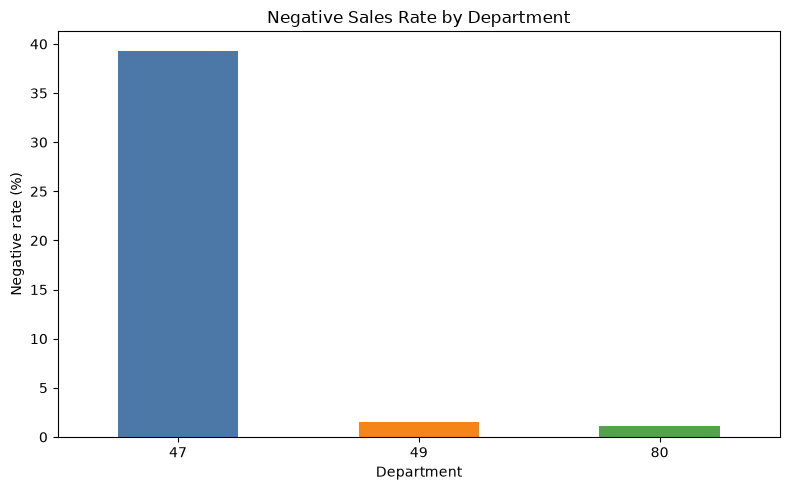

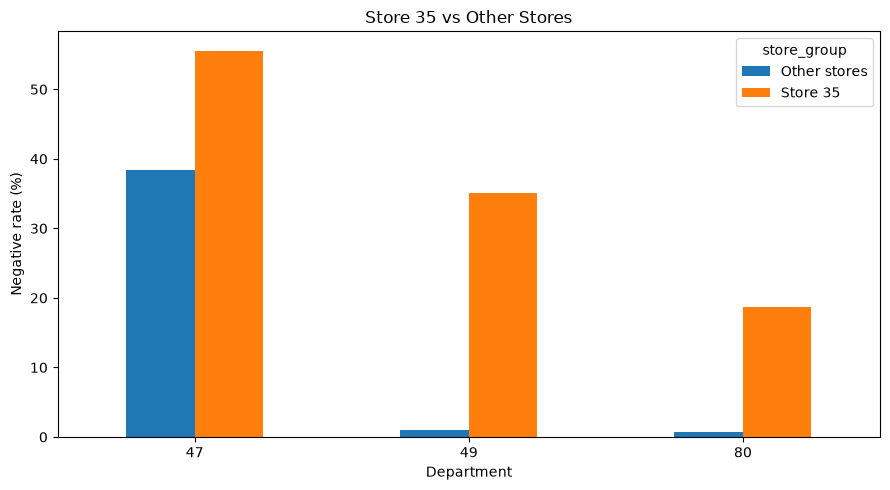

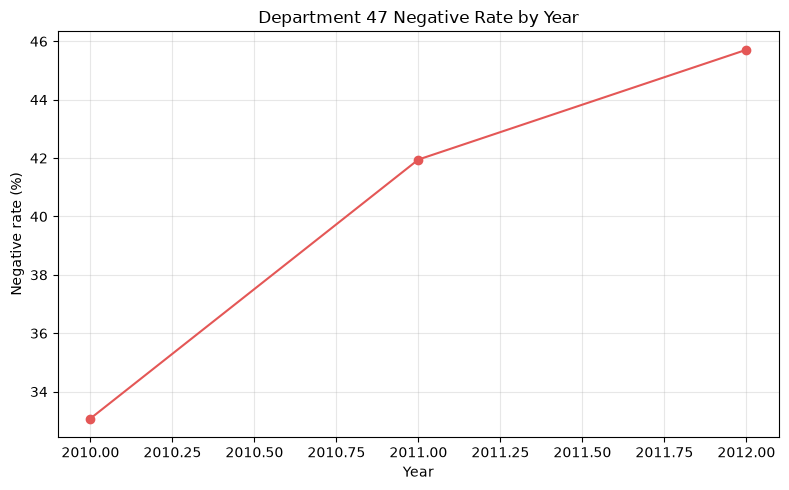

ANALYSIS COMPLETED

OVERALL DEPARTMENT SUMMARY


,total_observations,negative_observations,negative_rate,negative_impact
Dept,,,,
47,646,254,39.32,-53188.06
49,4482,67,1.49,-1455.98
80,5891,68,1.15,-4231.48



STORE 35 VS OTHER STORES


total_observations  negative_observations  negative_rate  \
Dept store_group                                                              
47   Other stores                 610                    234          38.36   
     Store 35                      36                     20          55.56   
49   Other stores                4425                     47           1.06   
     Store 35                      57                     20          35.09   
80   Other stores                5757                     43           0.75   
     Store 35                     134                     25          18.66   

                   negative_impact  
Dept store_group                    
47   Other stores        -47994.91  
     Store 35             -5193.15  
49   Other stores          -895.33  
     Store 35              -560.65  
80   Other stores         -2359.84  
     Store 35             -1871.64


DEPARTMENT 47 YEARLY TREND


,total_observations,negative_observations,negative_rate,negative_impact
Year,,,,
2010,266,88,33.08,-21670.69
2011,205,86,41.95,-20176.10
2012,175,80,45.71,-11341.27



20 LARGEST NEGATIVE RECORDS


,Store,Dept,Date,Weekly_Sales,IsHoliday
336495,35,47,2011-09-02,-3924.0,False
417801,45,47,2010-02-26,-1750.0,False
153916,16,47,2012-03-09,-1699.0,False
16297,2,47,2010-11-19,-1098.0,False
16295,2,47,2010-10-15,-1098.0,False
16291,2,47,2010-07-30,-1098.0,False
35561,4,47,2010-09-17,-898.0,False
6048,1,47,2010-02-19,-863.0,False
93573,10,47,2010-03-05,-798.0,False
93591,10,47,2011-08-05,-798.0,False



Files saved inside: negative_sales_outputs


In [163]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# SETTINGS
# -----------------------------
selected_departments = [47, 49, 80]
focus_store = 35
output_folder = "negative_sales_outputs"

os.makedirs(output_folder, exist_ok=True)

df['Date'] = pd.to_datetime(df['Date'])

selected_data = df[df['Dept'].isin(selected_departments)].copy()

selected_data['store_group'] = selected_data['Store'].apply(
    lambda store: f"Store {focus_store}"
    if store == focus_store
    else "Other stores"
)

# -----------------------------
# 1. OVERALL DEPARTMENT SUMMARY
# -----------------------------
department_summary = (
    selected_data.groupby('Dept')['Weekly_Sales']
    .agg(
        total_observations='count',
        negative_observations=lambda x: (x < 0).sum(),
        negative_rate=lambda x: (x < 0).mean() * 100,
        negative_impact=lambda x: x[x < 0].sum()
    )
    .round(2)
)

# -----------------------------
# 2. STORE 35 VS OTHER STORES
# -----------------------------
store_comparison = (
    selected_data
    .groupby(['Dept', 'store_group'])['Weekly_Sales']
    .agg(
        total_observations='count',
        negative_observations=lambda x: (x < 0).sum(),
        negative_rate=lambda x: (x < 0).mean() * 100,
        negative_impact=lambda x: x[x < 0].sum()
    )
    .round(2)
)

# -----------------------------
# 3. DEPARTMENT 47 BY YEAR
# -----------------------------
dept47 = df[df['Dept'] == 47].copy()
dept47['Year'] = dept47['Date'].dt.year

dept47_yearly = (
    dept47.groupby('Year')['Weekly_Sales']
    .agg(
        total_observations='count',
        negative_observations=lambda x: (x < 0).sum(),
        negative_rate=lambda x: (x < 0).mean() * 100,
        negative_impact=lambda x: x[x < 0].sum()
    )
    .round(2)
)

# -----------------------------
# 4. DEPARTMENT 47 BY STORE
# -----------------------------
dept47_by_store = (
    dept47.groupby('Store')['Weekly_Sales']
    .agg(
        total_observations='count',
        negative_observations=lambda x: (x < 0).sum(),
        negative_rate=lambda x: (x < 0).mean() * 100,
        negative_impact=lambda x: x[x < 0].sum()
    )
    .sort_values('negative_rate', ascending=False)
    .round(2)
)

# -----------------------------
# 5. LARGEST NEGATIVE RECORDS
# -----------------------------
negative_records = selected_data[
    selected_data['Weekly_Sales'] < 0
].copy()

outlier_columns = [
    'Store',
    'Dept',
    'Date',
    'Weekly_Sales',
    'IsHoliday'
]

largest_negative_records = (
    negative_records[outlier_columns]
    .sort_values('Weekly_Sales')
    .head(20)
)

# -----------------------------
# 6. SAVE TABLES
# -----------------------------
department_summary.to_csv(
    f"{output_folder}/department_summary.csv"
)

store_comparison.to_csv(
    f"{output_folder}/store35_vs_other_stores.csv"
)

dept47_yearly.to_csv(
    f"{output_folder}/dept47_yearly_summary.csv"
)

dept47_by_store.to_csv(
    f"{output_folder}/dept47_store_summary.csv"
)

largest_negative_records.to_csv(
    f"{output_folder}/largest_negative_records.csv",
    index=False
)

# -----------------------------
# 7. CREATE CHARTS
# -----------------------------
department_summary['negative_rate'].plot(
    kind='bar',
    color=['#4C78A8', '#F58518', '#54A24B'],
    figsize=(8, 5)
)

plt.title('Negative Sales Rate by Department')
plt.xlabel('Department')
plt.ylabel('Negative rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(
    f"{output_folder}/department_negative_rates.png",
    dpi=300
)
plt.show()

comparison_chart = (
    store_comparison
    .reset_index()
    .pivot(
        index='Dept',
        columns='store_group',
        values='negative_rate'
    )
)

comparison_chart.plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Store 35 vs Other Stores')
plt.xlabel('Department')
plt.ylabel('Negative rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(
    f"{output_folder}/store35_comparison.png",
    dpi=300
)
plt.show()

dept47_yearly['negative_rate'].plot(
    kind='line',
    marker='o',
    figsize=(8, 5),
    color='#E45756'
)

plt.title('Department 47 Negative Rate by Year')
plt.xlabel('Year')
plt.ylabel('Negative rate (%)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    f"{output_folder}/dept47_yearly_trend.png",
    dpi=300
)
plt.show()

# -----------------------------
# 8. DISPLAY FINAL RESULTS
# -----------------------------
print("ANALYSIS COMPLETED")
print("=" * 50)

print("\nOVERALL DEPARTMENT SUMMARY")
display(department_summary)

print("\nSTORE 35 VS OTHER STORES")
display(store_comparison)

print("\nDEPARTMENT 47 YEARLY TREND")
display(dept47_yearly)

print("\n20 LARGEST NEGATIVE RECORDS")
display(largest_negative_records)

print("\nFiles saved inside:", output_folder)

In [164]:
weekly_sales = (
    df.groupby('Date')['Weekly_Sales']
    .sum()
    .sort_index()
)

weekly_sales.head()

Date
2010-02-05    49750740.50
2010-02-12    48336677.63
2010-02-19    48276993.78
2010-02-26    43968571.13
2010-03-05    46871470.30
Name: Weekly_Sales, dtype: float64

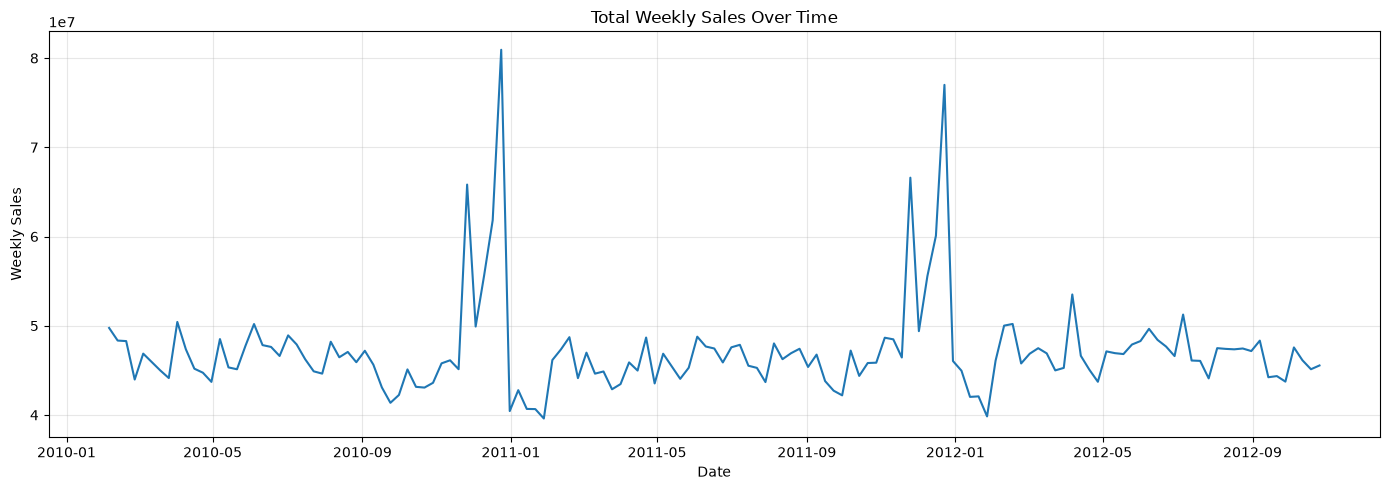

In [165]:
plt.figure(figsize=(14, 5))
plt.plot(weekly_sales.index, weekly_sales.values)

plt.title('Total Weekly Sales Over Time')
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [167]:
test_weeks = 12

train_sales = weekly_sales.iloc[:-test_weeks]
test_sales = weekly_sales.iloc[-test_weeks:]

print("Training period:")
print(train_sales.index.min(), "to", train_sales.index.max())

print("\nTesting period:")
print(test_sales.index.min(), "to", test_sales.index.max())

print("\nNumber of training weeks:", len(train_sales))
print("Number of testing weeks:", len(test_sales))

Training period:
2010-02-05 00:00:00 to 2012-08-03 00:00:00

Testing period:
2012-08-10 00:00:00 to 2012-10-26 00:00:00

Number of training weeks: 131
Number of testing weeks: 12


In [168]:
import numpy as np

seasonal_naive_predictions = pd.Series(
    [
        weekly_sales.get(
            date - pd.Timedelta(weeks=52),
            np.nan
        )
        for date in test_sales.index
    ],
    index=test_sales.index,
    name='Predicted_Sales'
)

baseline_results = pd.DataFrame({
    'Actual_Sales': test_sales,
    'Predicted_Sales': seasonal_naive_predictions
})

baseline_results

,Actual_Sales,Predicted_Sales
Date,,
2012-08-10,47403451.04,46249569.21
2012-08-17,47354452.05,46917347.62
2012-08-24,47447323.60,47416948.45
2012-08-31,47159639.43,45376623.27
2012-09-07,48330059.31,46763227.53
2012-09-14,44226038.65,43793960.08
2012-09-21,44354547.11,42718096.73
2012-09-28,43734899.40,42195830.81
2012-10-05,47566639.31,47211688.36


In [169]:
errors = (
    baseline_results['Actual_Sales']
    - baseline_results['Predicted_Sales']
)

mae = np.mean(np.abs(errors))
rmse = np.sqrt(np.mean(errors ** 2))

mape = np.mean(
    np.abs(
        errors / baseline_results['Actual_Sales']
    )
) * 100

print(f"Baseline MAE: {mae:,.2f}")
print(f"Baseline RMSE: {rmse:,.2f}")
print(f"Baseline MAPE: {mape:.2f}%")

Baseline MAE: 974,641.62
Baseline RMSE: 1,160,987.12
Baseline MAPE: 2.12%


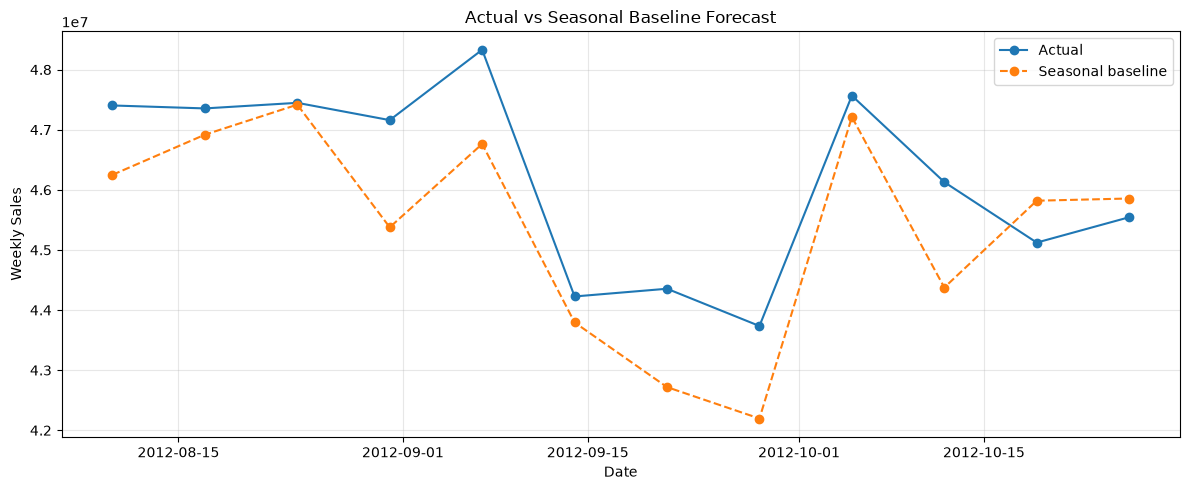

In [170]:
plt.figure(figsize=(12, 5))

plt.plot(
    baseline_results.index,
    baseline_results['Actual_Sales'],
    marker='o',
    label='Actual'
)

plt.plot(
    baseline_results.index,
    baseline_results['Predicted_Sales'],
    marker='o',
    linestyle='--',
    label='Seasonal baseline'
)

plt.title('Actual vs Seasonal Baseline Forecast')
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [172]:
model_data = pd.DataFrame({
    'Weekly_Sales': weekly_sales
})

model_data['Year'] = model_data.index.year
model_data['Month'] = model_data.index.month
model_data['Week'] = model_data.index.isocalendar().week.astype(int)

# Sales from the same week last year
model_data['Last_Year_Sales'] = (
    model_data['Weekly_Sales'].shift(52)
)

model_data = model_data.dropna()

model_data.head()

,Weekly_Sales,Year,Month,Week,Last_Year_Sales
Date,,,,,
2011-02-04,46153111.12,2011,2,5,49750740.50
2011-02-11,47336192.79,2011,2,6,48336677.63
2011-02-18,48716164.12,2011,2,7,48276993.78
2011-02-25,44125859.84,2011,2,8,43968571.13
2011-03-04,46980603.74,2011,3,9,46871470.30


In [173]:
train_model = model_data.iloc[:-12]
test_model = model_data.iloc[-12:]

features = [
    'Year',
    'Month',
    'Week',
    'Last_Year_Sales'
]

X_train = train_model[features]
y_train = train_model['Weekly_Sales']

X_test = test_model[features]
y_test = test_model['Weekly_Sales']

In [176]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

In [177]:
linear_mae = np.mean(
    np.abs(y_test - linear_predictions)
)

linear_rmse = np.sqrt(
    np.mean((y_test - linear_predictions) ** 2)
)

linear_mape = np.mean(
    np.abs((y_test - linear_predictions) / y_test)
) * 100

print(f"Linear Regression MAE: {linear_mae:,.2f}")
print(f"Linear Regression RMSE: {linear_rmse:,.2f}")
print(f"Linear Regression MAPE: {linear_mape:.2f}%")

print(f"\nSeasonal Baseline MAPE: {mape:.2f}%")

Linear Regression MAE: 702,395.39
Linear Regression RMSE: 890,071.31
Linear Regression MAPE: 1.53%

Seasonal Baseline MAPE: 2.12%


In [178]:
from sklearn.tree import DecisionTreeRegressor

tree_model = DecisionTreeRegressor(
    max_depth=4,
    random_state=42
)

tree_model.fit(X_train, y_train)

tree_predictions = tree_model.predict(X_test)

tree_mape = np.mean(
    np.abs(
        (y_test - tree_predictions) / y_test
    )
) * 100

print(f"Decision Tree MAPE: {tree_mape:.2f}%")
print(f"Linear Regression MAPE: {linear_mape:.2f}%")
print(f"Seasonal Baseline MAPE: {mape:.2f}%")

Decision Tree MAPE: 2.43%
Linear Regression MAPE: 1.53%
Seasonal Baseline MAPE: 2.12%


In [179]:
from sklearn.ensemble import RandomForestRegressor

forest_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

forest_model.fit(X_train, y_train)

forest_predictions = forest_model.predict(X_test)

forest_mae = np.mean(
    np.abs(y_test - forest_predictions)
)

forest_rmse = np.sqrt(
    np.mean((y_test - forest_predictions) ** 2)
)

forest_mape = np.mean(
    np.abs(
        (y_test - forest_predictions) / y_test
    )
) * 100

print(f"Random Forest MAE: {forest_mae:,.2f}")
print(f"Random Forest RMSE: {forest_rmse:,.2f}")
print(f"Random Forest MAPE: {forest_mape:.2f}%")

print(f"\nLinear Regression MAPE: {linear_mape:.2f}%")
print(f"Decision Tree MAPE: {tree_mape:.2f}%")
print(f"Seasonal Baseline MAPE: {mape:.2f}%")

Random Forest MAE: 718,644.89
Random Forest RMSE: 1,116,383.58
Random Forest MAPE: 1.57%

Linear Regression MAPE: 1.53%
Decision Tree MAPE: 2.43%
Seasonal Baseline MAPE: 2.12%


In [180]:
model_results = pd.DataFrame({
    'Model': [
        'Seasonal Baseline',
        'Linear Regression',
        'Decision Tree',
        'Random Forest'
    ],
    'MAPE': [
        mape,
        linear_mape,
        tree_mape,
        forest_mape
    ]
}).sort_values('MAPE')

model_results

,Model,MAPE
1,Linear Regression,1.527793
3,Random Forest,1.571589
0,Seasonal Baseline,2.117132
2,Decision Tree,2.429714


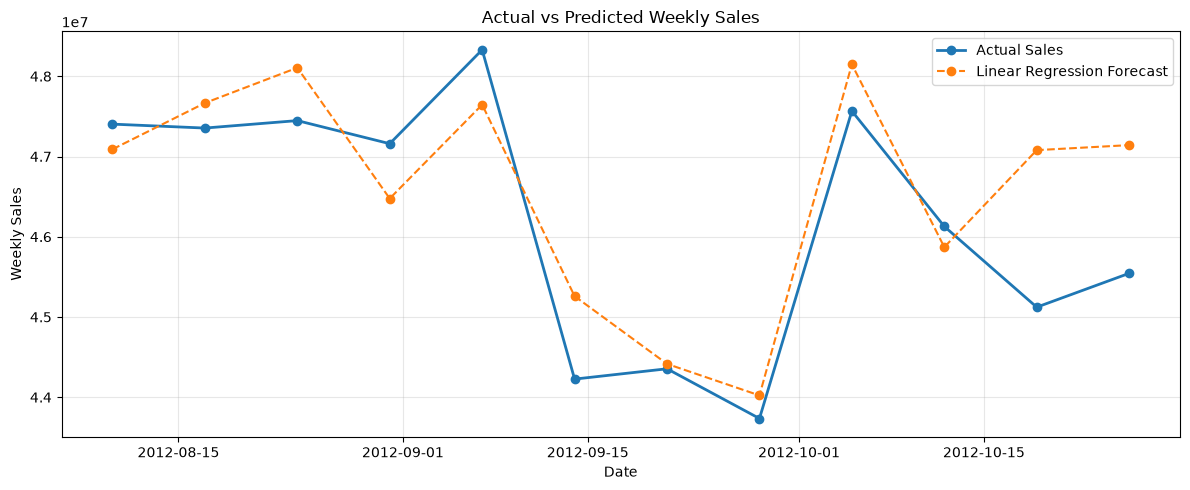

In [181]:
plt.figure(figsize=(12, 5))

plt.plot(
    y_test.index,
    y_test,
    marker='o',
    linewidth=2,
    label='Actual Sales'
)

plt.plot(
    y_test.index,
    linear_predictions,
    marker='o',
    linestyle='--',
    label='Linear Regression Forecast'
)

plt.title('Actual vs Predicted Weekly Sales')
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    'negative_sales_outputs/final_forecast.png',
    dpi=300
)

plt.show()

In [182]:
model_results.to_csv(
    'negative_sales_outputs/model_comparison.csv',
    index=False
)

## Retraining


In [183]:
final_model = LinearRegression()

final_model.fit(
    model_data[features],
    model_data['Weekly_Sales']
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[ -193.97, 6289.06,27799.22, 0.82]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['Year','Month','Week','Last_Year_Sales']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,8.508e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [184]:
future_dates = pd.date_range(
    start=weekly_sales.index.max() + pd.Timedelta(weeks=1),
    periods=12,
    freq='W-FRI'
)

future_data = pd.DataFrame(index=future_dates)

future_data['Year'] = future_data.index.year
future_data['Month'] = future_data.index.month
future_data['Week'] = (
    future_data.index.isocalendar().week.astype(int)
)

future_data['Last_Year_Sales'] = [
    weekly_sales.get(
        date - pd.Timedelta(weeks=52)
    )
    for date in future_data.index
]

future_data

,Year,Month,Week,Last_Year_Sales
2012-11-02,2012,11,44,48655544.30
2012-11-09,2012,11,45,48474224.75
2012-11-16,2012,11,46,46438980.56
2012-11-23,2012,11,47,66593605.26
2012-11-30,2012,11,48,49390556.49
2012-12-07,2012,12,49,55561147.70
2012-12-14,2012,12,50,60085695.94
2012-12-21,2012,12,51,76998241.31
2012-12-28,2012,12,52,46042461.04
2013-01-04,2013,1,1,44955421.95


In [187]:
import os

os.makedirs('negative_sales_outputs', exist_ok=True)

# Train final model using all available data
final_model = LinearRegression()

final_model.fit(
    model_data[features],
    model_data['Weekly_Sales']
)

# Create next 12 weekly dates
future_dates = pd.date_range(
    start=weekly_sales.index.max() + pd.Timedelta(weeks=1),
    periods=12,
    freq='W-FRI'
)

# Create future features
future_data = pd.DataFrame(index=future_dates)

future_data['Year'] = future_data.index.year
future_data['Month'] = future_data.index.month
future_data['Week'] = (
    future_data.index.isocalendar().week.astype(int)
)

future_data['Last_Year_Sales'] = [
    weekly_sales.get(
        date - pd.Timedelta(weeks=52)
    )
    for date in future_dates
]

# Check for missing feature values
print("Missing values:")
print(future_data.isnull().sum())

# Generate predictions
future_predictions = final_model.predict(
    future_data[features]
)

# Create final forecast table
future_forecast = pd.DataFrame({
    'Date': future_dates,
    'Predicted_Weekly_Sales': future_predictions
})

# Save the results
future_forecast.to_csv(
    'negative_sales_outputs/future_12_week_forecast.csv',
    index=False
)

future_forecast

Missing values:
Year               0
Month              0
Week               0
Last_Year_Sales    0
dtype: int64


,Date,Predicted_Weekly_Sales
0,2012-11-02,4.933167e+07
1,2012-11-09,4.921070e+07
2,2012-11-16,4.756861e+07
3,2012-11-23,6.413298e+07
4,2012-11-30,5.004593e+07
5,2012-12-07,5.514290e+07
6,2012-12-14,5.888302e+07
7,2012-12-21,7.278731e+07
8,2012-12-28,4.741635e+07
9,2013-01-04,4.503732e+07


In [185]:
future_data.isnull().sum()

Year               0
Month              0
Week               0
Last_Year_Sales    0
dtype: int64

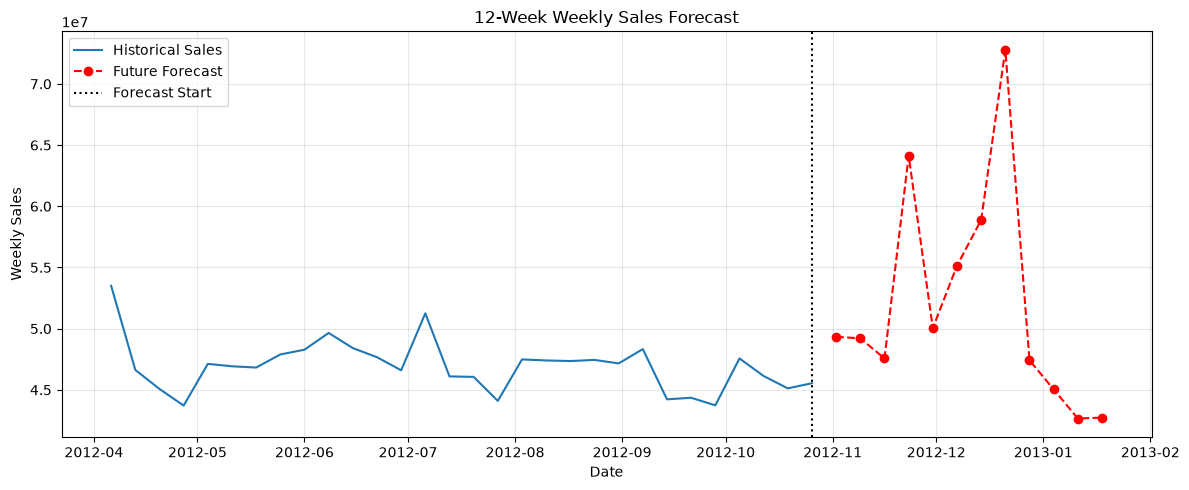

In [188]:
future_forecast.to_csv(
    'negative_sales_outputs/future_12_week_forecast.csv',
    index=False
)

plt.figure(figsize=(12, 5))

plt.plot(
    weekly_sales.tail(30).index,
    weekly_sales.tail(30).values,
    label='Historical Sales'
)

plt.plot(
    future_dates,
    future_predictions,
    marker='o',
    linestyle='--',
    color='red',
    label='Future Forecast'
)

plt.axvline(
    weekly_sales.index.max(),
    color='black',
    linestyle=':',
    label='Forecast Start'
)

plt.title('12-Week Weekly Sales Forecast')
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    'negative_sales_outputs/future_12_week_forecast.png',
    dpi=300
)

plt.show()

In [189]:
historical_export = weekly_sales.reset_index()
historical_export.columns = [
    'Date',
    'Weekly_Sales'
]

historical_export['Data_Type'] = 'Historical'

forecast_export = future_forecast.copy()
forecast_export.columns = [
    'Date',
    'Weekly_Sales'
]

forecast_export['Data_Type'] = 'Forecast'

powerbi_sales_data = pd.concat(
    [historical_export, forecast_export],
    ignore_index=True
)

powerbi_sales_data.to_csv(
    'negative_sales_outputs/powerbi_sales_forecast.csv',
    index=False
)

powerbi_sales_data.tail(15)

,Date,Weekly_Sales,Data_Type
140,2012-10-12,4.612851e+07,Historical
141,2012-10-19,4.512241e+07,Historical
142,2012-10-26,4.554412e+07,Historical
143,2012-11-02,4.933167e+07,Forecast
144,2012-11-09,4.921070e+07,Forecast
145,2012-11-16,4.756861e+07,Forecast
146,2012-11-23,6.413298e+07,Forecast
147,2012-11-30,5.004593e+07,Forecast
148,2012-12-07,5.514290e+07,Forecast
149,2012-12-14,5.888302e+07,Forecast


In [192]:
powerbi_file = (
    'negative_sales_outputs/'
    'walmart_powerbi_dashboard.xlsx'
)

with pd.ExcelWriter(
    powerbi_file,
    engine='openpyxl'
) as writer:

    powerbi_sales_data.to_excel(
        writer,
        sheet_name='Sales_Forecast',
        index=False
    )

    model_results.to_excel(
        writer,
        sheet_name='Model_Results',
        index=False
    )

    store_comparison.reset_index().to_excel(
        writer,
        sheet_name='Negative_Sales',
        index=False
    )

    dept47_yearly.reset_index().to_excel(
        writer,
        sheet_name='Dept47_Yearly',
        index=False
    )

print("Power BI workbook created:")
print(powerbi_file)

Power BI workbook created:
negative_sales_outputs/walmart_powerbi_dashboard.xlsx
